# AgriGenius: Complete AI/ML Classification & Regression Pipeline (With Rich Visualizations)
**Project:** AgriGenius — Plant Disease Detection and Farm Decision Support System  
**Dataset:** `abdallahalidev/plantvillage-dataset` (Kaggle)  
**Tasks:**
1. **Exploratory Visual & Embedding Analysis** (Class balance, color vs. segmented masks, PCA 2D feature cluster projection)
2. **Supervised Multi-Class Classification** (Model comparison chart, confusion matrix heatmap, per-class F1 breakdown, misclassified failure gallery)
3. **Supervised Regression** (Discoloration proxy distributions, actual vs. predicted scatter, residual diagnostics, worst prediction gallery)


In [1]:
# Cell 1: Install Dependencies, Imports & Experiment Configuration
!pip install -q kagglehub opencv-python-headless scikit-learn matplotlib seaborn pandas pillow

import os
import json
import hashlib
import random
from pathlib import Path

import cv2
import joblib
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Global Plot Styling ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# --- Global Configuration ---
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
KAGGLE_DATASET_SLUG = "abdallahalidev/plantvillage-dataset"

# Set to None to train on ALL classes in the dataset
SELECTED_CLASSES = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
]
MAX_IMAGES_PER_CLASS = 200

ARTIFACT_DIR = Path("agrigenius_ml_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [2]:
# Cell 2: Download via Kaggle API & Dynamically Resolve Directory Layout
dataset_root = Path(kagglehub.dataset_download(KAGGLE_DATASET_SLUG))
print("Downloaded dataset root:", dataset_root)

def find_named_subdir(root: Path, target_name: str) -> Path | None:
    for p in root.rglob(target_name):
        if p.is_dir():
            subdirs = [d for d in p.iterdir() if d.is_dir()]
            if len(subdirs) >= 2:
                return p
    return None

COLOR_DIR = find_named_subdir(dataset_root, "color")
SEGMENTED_DIR = find_named_subdir(dataset_root, "segmented")

assert COLOR_DIR is not None, f"Could not locate 'color' folder inside {dataset_root}"
print("Resolved COLOR_DIR    :", COLOR_DIR)
print("Resolved SEGMENTED_DIR:", SEGMENTED_DIR)

all_classes = sorted([d.name for d in COLOR_DIR.iterdir() if d.is_dir()])
print(f"\nTotal discovered classes in COLOR_DIR: {len(all_classes)}")
for idx, cls_name in enumerate(all_classes[:10]):
    print(f"  {idx+1:2d}. {cls_name}")

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Downloaded dataset root: /kaggle/input/plantvillage-dataset
Resolved COLOR_DIR    : /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Resolved SEGMENTED_DIR: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented

Total discovered classes in COLOR_DIR: 38
   1. Apple___Apple_scab
   2. Apple___Black_rot
   3. Apple___Cedar_apple_rust
   4. Apple___healthy
   5. Blueberry___healthy
   6. Cherry_(including_sour)___Powdery_mildew
   7. Cherry_(including_sour)___healthy
   8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
   9. Corn_(maize)___Common_rust_
  10. Corn_(maize)___Northern_Leaf_Blight


Clean unique images collected : 1152
Corrupted images skipped      : 0
Exact duplicates removed      : 0


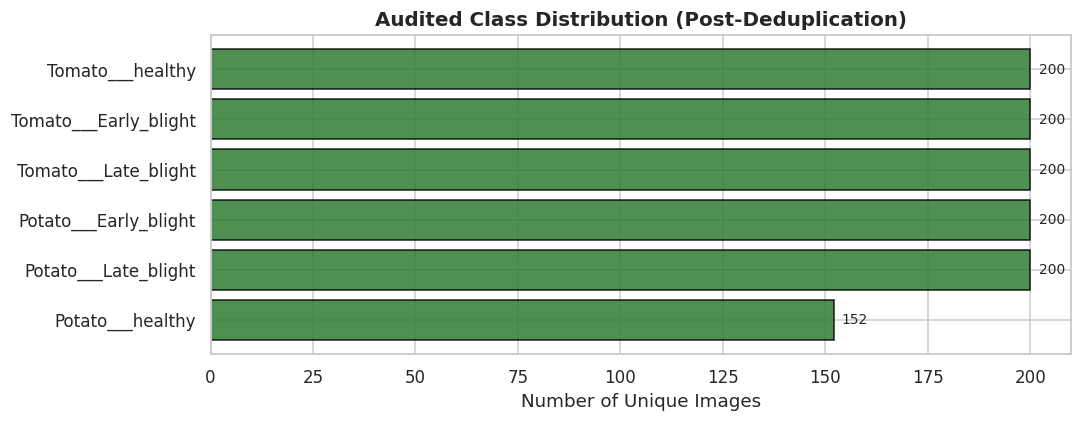

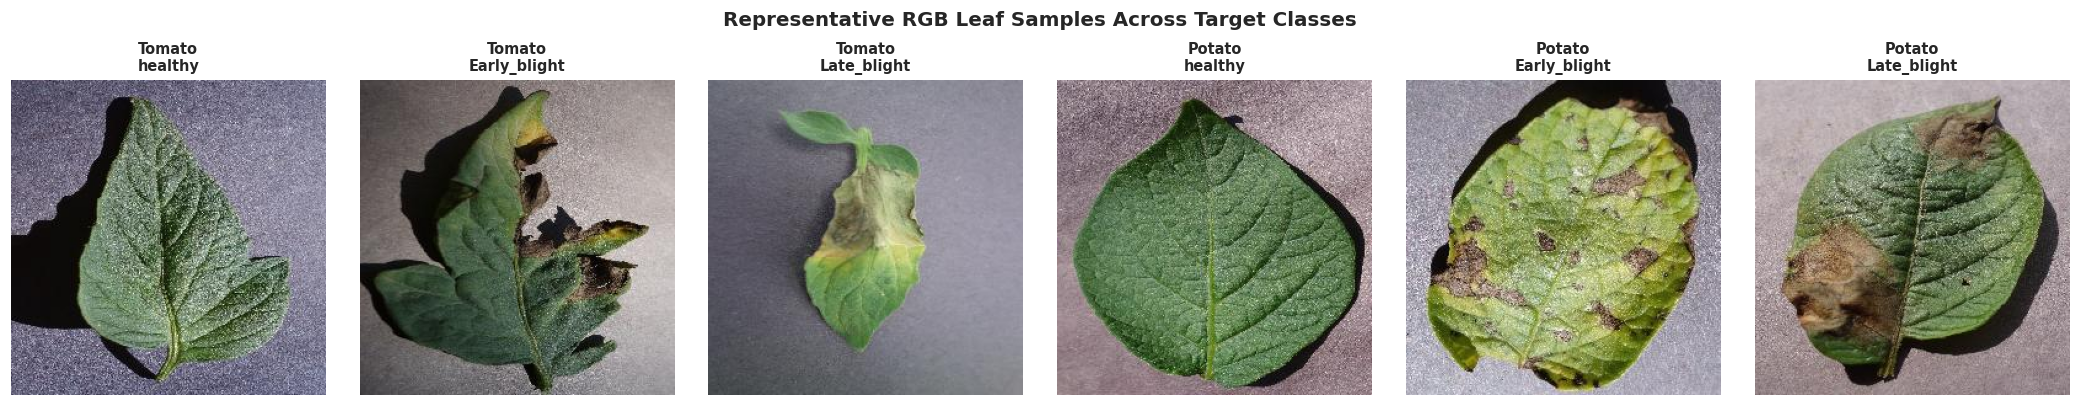

In [3]:
# Cell 3: Data Integrity Audit, Exact Deduplication & Visual Sample Grid
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def normalize_stem(path: Path) -> str:
    stem = path.stem.lower().strip()
    return stem.replace("_final_masked", "").strip()

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

seg_index = {}
if SEGMENTED_DIR is not None:
    for cls_dir in SEGMENTED_DIR.iterdir():
        if cls_dir.is_dir():
            for fp in cls_dir.iterdir():
                if fp.is_file() and fp.suffix.lower() in VALID_EXTS:
                    seg_index[(cls_dir.name, normalize_stem(fp))] = fp

target_classes = all_classes if SELECTED_CLASSES is None else [
    c for c in SELECTED_CLASSES if (COLOR_DIR / c).is_dir()
]
assert len(target_classes) >= 2, "Check SELECTED_CLASSES against discovered folders."

records = []
corrupted_count = 0
duplicate_count = 0
seen_hashes = set()

for cls_name in target_classes:
    cls_dir = COLOR_DIR / cls_name
    img_files = sorted([
        fp for fp in cls_dir.iterdir()
        if fp.is_file() and fp.suffix.lower() in VALID_EXTS
    ])

    rng = random.Random(SEED)
    rng.shuffle(img_files)

    kept_in_class = 0
    for fp in img_files:
        if MAX_IMAGES_PER_CLASS is not None and kept_in_class >= MAX_IMAGES_PER_CLASS:
            break

        try:
            with Image.open(fp) as im:
                im.verify()
            with Image.open(fp) as im:
                w, h = im.size
                mode = im.mode
        except Exception:
            corrupted_count += 1
            continue

        file_hash = sha256_file(fp)
        if file_hash in seen_hashes:
            duplicate_count += 1
            continue
        seen_hashes.add(file_hash)

        seg_path = seg_index.get((cls_name, normalize_stem(fp)), None)
        records.append({
            "color_path": str(fp),
            "segmented_path": str(seg_path) if seg_path else None,
            "class_name": cls_name,
            "is_healthy": int("healthy" in cls_name.lower()),
            "width": w,
            "height": h,
            "mode": mode,
            "sha256": file_hash,
        })
        kept_in_class += 1

df = pd.DataFrame(records)
print(f"Clean unique images collected : {len(df)}")
print(f"Corrupted images skipped      : {corrupted_count}")
print(f"Exact duplicates removed      : {duplicate_count}")

# --- Visualization 1: Class Distribution Bar Chart ---
fig, ax = plt.subplots(figsize=(10, 4))
counts = df["class_name"].value_counts()
bars = ax.barh(counts.index, counts.values, color="#2e7d32", edgecolor="black", alpha=0.85)
ax.set_title("Audited Class Distribution (Post-Deduplication)", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Unique Images")
ax.invert_yaxis()
for bar in bars:
    ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# --- Visualization 2: Sample Leaf Gallery (1 Random Leaf per Class) ---
n_cls = len(target_classes)
fig, axes = plt.subplots(1, n_cls, figsize=(3.2 * n_cls, 3.6))
if n_cls == 1:
    axes = [axes]
for ax, cls_name in zip(axes, target_classes):
    sample_row = df[df["class_name"] == cls_name].sample(1, random_state=SEED).iloc[0]
    img = Image.open(sample_row["color_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(cls_name.replace("___", "\n"), fontsize=9.5, fontweight="bold")
    ax.axis("off")
plt.suptitle("Representative RGB Leaf Samples Across Target Classes", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Regression target engineered successfully for 1152 samples.


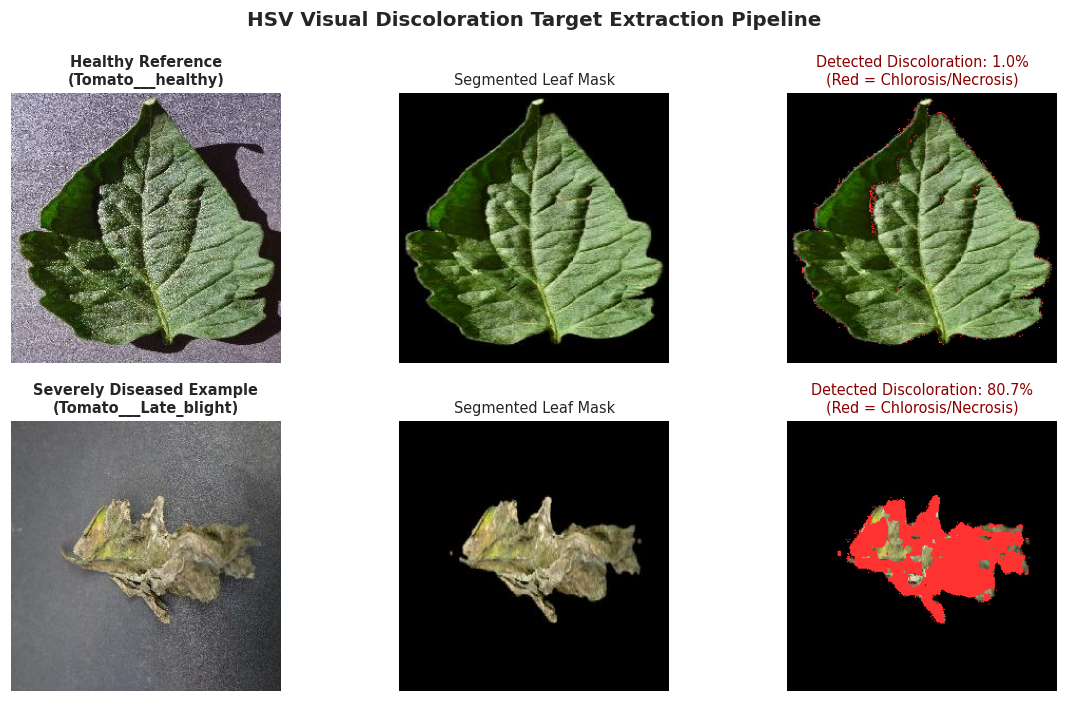

/tmp/ipykernel_848/1974804176.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y="class_name", x="discoloration_pct", order=order, palette="YlOrRd")


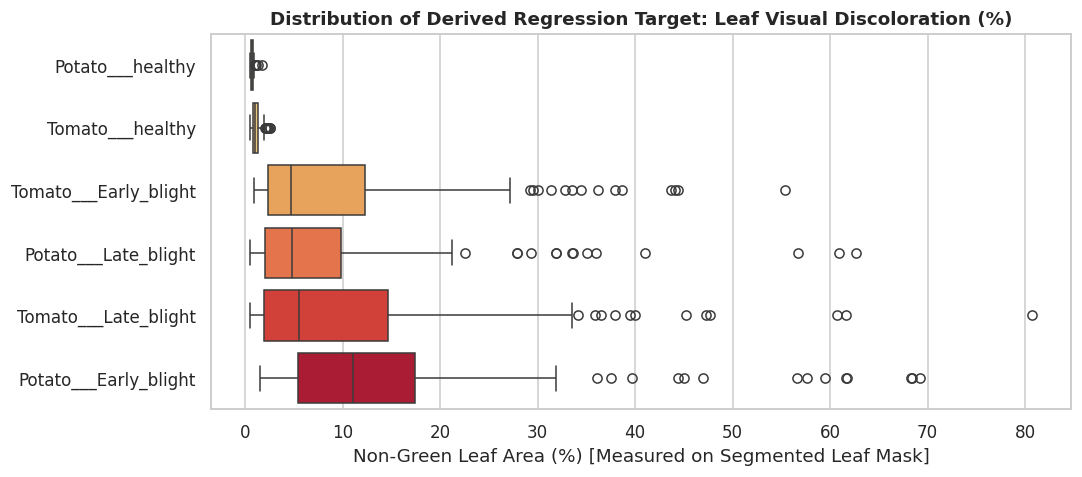

In [4]:
# Cell 4: Regression Target Engineering & HSV Mask Diagnostic Visualization
def compute_discoloration_details(segmented_path: str | None, color_path: str):
    src_path = segmented_path if segmented_path is not None else color_path
    with Image.open(src_path) as im:
        rgb = np.array(im.convert("RGB"))

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

    if segmented_path is not None:
        leaf_mask = v > 15
    else:
        leaf_mask = (s > 30) & (v > 20)

    leaf_pixels = int(np.sum(leaf_mask))
    if leaf_pixels == 0:
        return np.nan, rgb, leaf_mask, np.zeros_like(leaf_mask)

    healthy_green_mask = leaf_mask & (h >= 28) & (h <= 90) & (s >= 25) & (v >= 25)
    healthy_pixels = int(np.sum(healthy_green_mask))
    discolored_mask = leaf_mask & (~healthy_green_mask)

    discolored_pct = 100.0 * (1.0 - (healthy_pixels / leaf_pixels))
    return float(np.clip(discolored_pct, 0.0, 100.0)), rgb, leaf_mask, discolored_mask

df["discoloration_pct"] = [
    compute_discoloration_details(sp, cp)[0]
    for sp, cp in zip(df["segmented_path"], df["color_path"])
]
df = df.dropna(subset=["discoloration_pct"]).reset_index(drop=True)
print("Regression target engineered successfully for", len(df), "samples.")

# --- Visualization 3: How the Discoloration Proxy Works (Healthy vs. Diseased Leaf Overlay) ---
healthy_row = df[df["is_healthy"] == 1].iloc[0]
diseased_row = df[df["is_healthy"] == 0].sort_values("discoloration_pct", ascending=False).iloc[0]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for r_idx, (label, row) in enumerate([("Healthy Reference", healthy_row), ("Severely Diseased Example", diseased_row)]):
    pct, seg_rgb, leaf_m, disc_m = compute_discoloration_details(row["segmented_path"], row["color_path"])
    orig_rgb = np.array(Image.open(row["color_path"]).convert("RGB"))
    overlay = seg_rgb.copy()
    overlay[disc_m] = [255, 50, 50]  # Highlight non-green lesion pixels in bright red

    axes[r_idx, 0].imshow(orig_rgb)
    axes[r_idx, 0].set_title(f"{label}\n({row['class_name']})", fontsize=9.5, fontweight="bold")
    axes[r_idx, 0].axis("off")

    axes[r_idx, 1].imshow(seg_rgb)
    axes[r_idx, 1].set_title("Segmented Leaf Mask", fontsize=9.5)
    axes[r_idx, 1].axis("off")

    axes[r_idx, 2].imshow(overlay)
    axes[r_idx, 2].set_title(f"Detected Discoloration: {pct:.1f}%\n(Red = Chlorosis/Necrosis)", fontsize=9.5, color="darkred")
    axes[r_idx, 2].axis("off")

plt.suptitle("HSV Visual Discoloration Target Extraction Pipeline", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# --- Visualization 4: Boxplot of Discoloration % Across Classes ---
plt.figure(figsize=(10, 4.5))
order = df.groupby("class_name")["discoloration_pct"].median().sort_values().index
sns.boxplot(data=df, y="class_name", x="discoloration_pct", order=order, palette="YlOrRd")
plt.title("Distribution of Derived Regression Target: Leaf Visual Discoloration (%)", fontsize=12, fontweight="bold")
plt.xlabel("Non-Green Leaf Area (%) [Measured on Segmented Leaf Mask]")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [5]:
# Cell 5: Stratified Leakage-Free Train / Validation / Test Split (70 / 15 / 15)
le = LabelEncoder()
df["label_id"] = le.fit_transform(df["class_name"])
class_names = list(le.classes_)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert set(train_df["sha256"]).isdisjoint(set(val_df["sha256"]))
assert set(train_df["sha256"]).isdisjoint(set(test_df["sha256"]))
print(f"Split sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Split sizes -> Train: 806 | Val: 173 | Test: 173


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Embeddings extracted. Shape: (806, 1280)


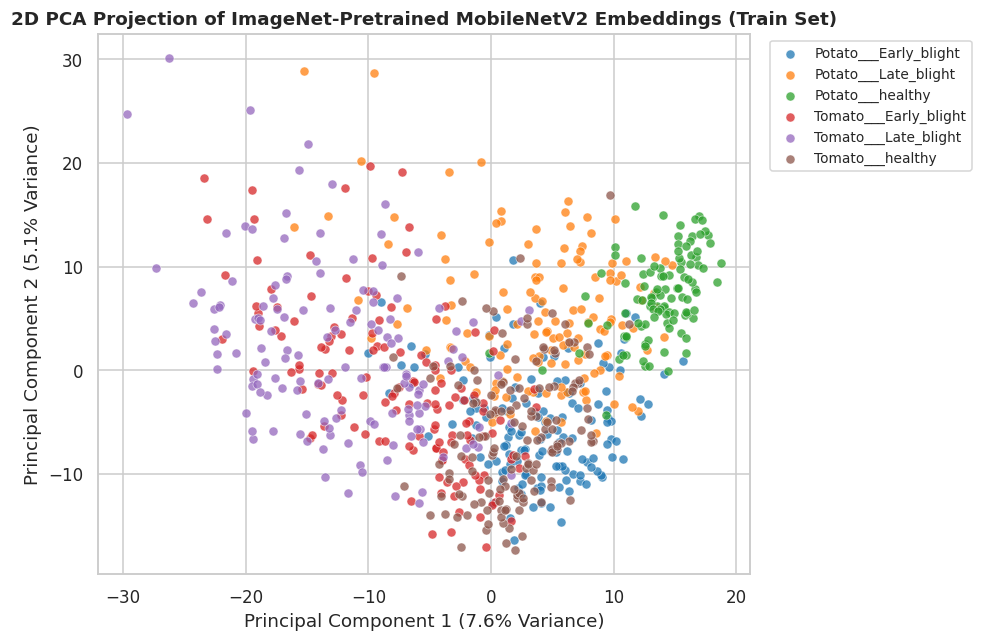

In [6]:
# Cell 6: MobileNetV2 Feature Extraction & 2D PCA Feature Space Projection
feature_extractor = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
)
feature_extractor.trainable = False

def extract_mobilenet_embeddings(paths: list[str], batch_size: int = BATCH_SIZE) -> np.ndarray:
    all_embeddings = []
    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start : start + batch_size]
        batch_imgs = []
        for p in batch_paths:
            with Image.open(p) as im:
                im = im.convert("RGB").resize(IMG_SIZE, Image.BILINEAR)
                batch_imgs.append(np.asarray(im, dtype=np.float32))
        batch_arr = preprocess_input(np.stack(batch_imgs, axis=0))
        emb = feature_extractor.predict(batch_arr, verbose=0)
        all_embeddings.append(emb)
    return np.vstack(all_embeddings)

X_train = extract_mobilenet_embeddings(train_df["color_path"].tolist())
X_val   = extract_mobilenet_embeddings(val_df["color_path"].tolist())
X_test  = extract_mobilenet_embeddings(test_df["color_path"].tolist())

y_cls_train = train_df["label_id"].values
y_cls_val   = val_df["label_id"].values
y_cls_test  = test_df["label_id"].values

y_reg_train = train_df["discoloration_pct"].values
y_reg_val   = val_df["discoloration_pct"].values
y_reg_test  = test_df["discoloration_pct"].values

print("Embeddings extracted. Shape:", X_train.shape)

# --- Visualization 5: 2D PCA Projection of MobileNetV2 Feature Embeddings ---
pca_vis = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2, random_state=SEED))])
X_train_2d = pca_vis.fit_transform(X_train)
var_exp = pca_vis.named_steps["pca"].explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))
palette = sns.color_palette("tab10", n_colors=len(class_names))
for idx, cls_name in enumerate(class_names):
    mask = y_cls_train == idx
    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        label=cls_name,
        alpha=0.75,
        s=35,
        color=palette[idx],
        edgecolors="w",
        linewidth=0.4,
    )
plt.title("2D PCA Projection of ImageNet-Pretrained MobileNetV2 Embeddings (Train Set)", fontsize=12, fontweight="bold")
plt.xlabel(f"Principal Component 1 ({var_exp[0]:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({var_exp[1]:.1f}% Variance)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

,Model,Val Accuracy,Val Macro F1
1,SVM (RBF Kernel),0.9538,0.9559
0,Logistic Regression (L2),0.9480,0.9499
2,Random Forest (PCA-100),0.8786,0.8800


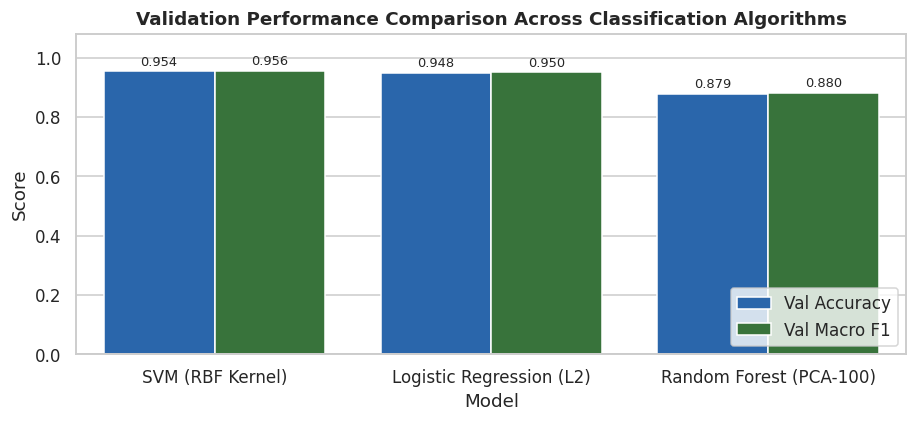


=== FINAL TEST CLASSIFICATION REPORT (SVM (RBF Kernel)) ===
                       precision    recall  f1-score   support

Potato___Early_blight     0.9677    1.0000    0.9836        30
 Potato___Late_blight     0.9333    0.9333    0.9333        30
     Potato___healthy     1.0000    0.9130    0.9545        23
Tomato___Early_blight     0.8000    0.9333    0.8615        30
 Tomato___Late_blight     0.9231    0.8000    0.8571        30
     Tomato___healthy     0.9667    0.9667    0.9667        30

             accuracy                         0.9249       173
            macro avg     0.9318    0.9244    0.9261       173
         weighted avg     0.9290    0.9249    0.9250       173



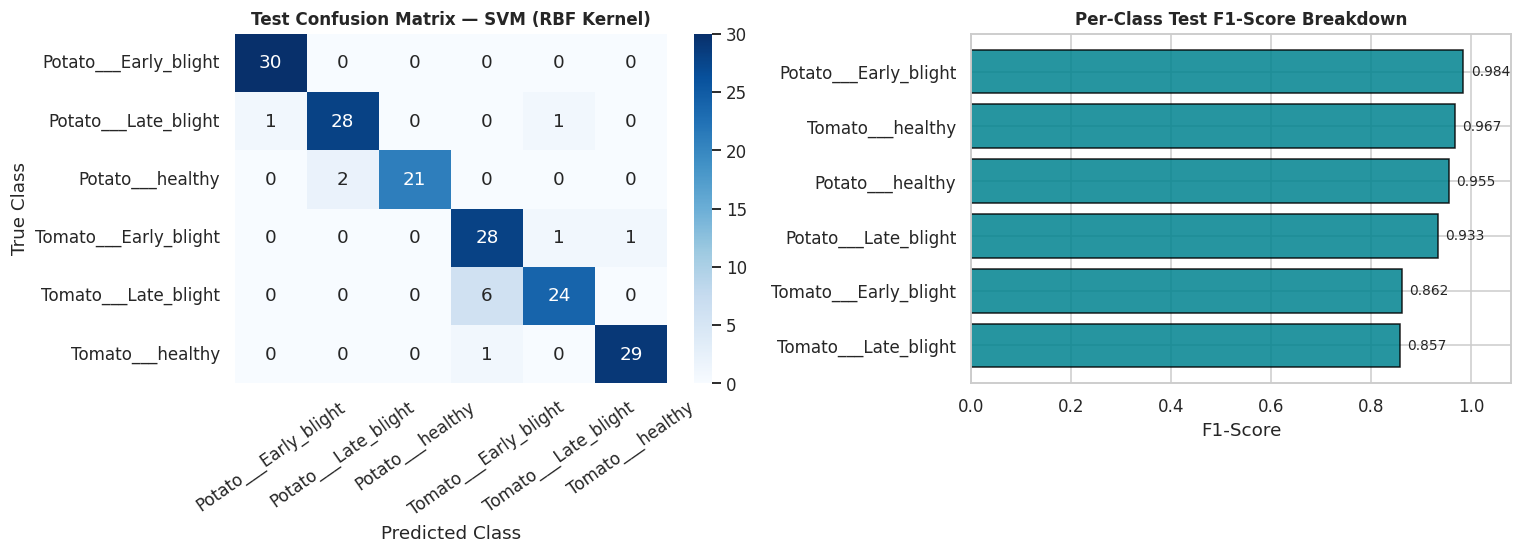

In [7]:
# Cell 7: Machine Learning Classification Pipeline & Rich Visual Diagnostics
pca_dim = min(100, X_train.shape[0] - 1, X_train.shape[1])

classifiers = {
    "Logistic Regression (L2)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    "SVM (RBF Kernel)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=3.0, class_weight="balanced", probability=True, random_state=SEED)),
    ]),
    "Random Forest (PCA-100)": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=pca_dim, random_state=SEED)),
        ("clf", RandomForestClassifier(n_estimators=250, class_weight="balanced", random_state=SEED, n_jobs=-1)),
    ]),
}

cls_val_results = []
fitted_classifiers = {}

for name, pipe in classifiers.items():
    pipe.fit(X_train, y_cls_train)
    val_pred = pipe.predict(X_val)
    acc = accuracy_score(y_cls_val, val_pred)
    prec, rec, f1_macro, _ = precision_recall_fscore_support(y_cls_val, val_pred, average="macro", zero_division=0)
    fitted_classifiers[name] = pipe
    cls_val_results.append({"Model": name, "Val Accuracy": round(acc, 4), "Val Macro F1": round(f1_macro, 4)})

cls_results_df = pd.DataFrame(cls_val_results).sort_values("Val Macro F1", ascending=False)
display(cls_results_df)

# --- Visualization 6: Grouped Bar Chart Comparing Classification Models ---
melted_cls = cls_results_df.melt(id_vars="Model", value_vars=["Val Accuracy", "Val Macro F1"], var_name="Metric", value_name="Score")
plt.figure(figsize=(8.5, 4))
ax = sns.barplot(data=melted_cls, x="Model", y="Score", hue="Metric", palette=["#1565c0", "#2e7d32"])
plt.ylim(0, 1.08)
plt.title("Validation Performance Comparison Across Classification Algorithms", fontsize=12, fontweight="bold")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# --- Evaluate Winner on Untouched Test Set ---
best_cls_name = cls_results_df.iloc[0]["Model"]
best_cls_model = fitted_classifiers[best_cls_name]
y_cls_test_pred = best_cls_model.predict(X_test)
print(f"\n=== FINAL TEST CLASSIFICATION REPORT ({best_cls_name}) ===")
print(classification_report(y_cls_test, y_cls_test_pred, target_names=class_names, digits=4, zero_division=0))

# --- Visualization 7 & 8: Test Confusion Matrix + Per-Class F1-Score Bar Chart ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

cm = confusion_matrix(y_cls_test, y_cls_test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f"Test Confusion Matrix — {best_cls_name}", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")
axes[0].tick_params(axis="x", rotation=35)

_, _, per_class_f1, _ = precision_recall_fscore_support(y_cls_test, y_cls_test_pred, zero_division=0)
f1_series = pd.Series(per_class_f1, index=class_names).sort_values()
bars = axes[1].barh(f1_series.index, f1_series.values, color="#00838f", edgecolor="black", alpha=0.85)
axes[1].set_xlim(0, 1.08)
axes[1].set_title("Per-Class Test F1-Score Breakdown", fontsize=11, fontweight="bold")
axes[1].set_xlabel("F1-Score")
for bar in bars:
    axes[1].text(bar.get_width() + 0.015, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

,Model,Val MAE,Val RMSE,Val R2
0,Ridge Regression (L2),3.878,5.683,0.6930
1,SVR (RBF Kernel),3.762,6.041,0.6531
2,Random Forest Regressor (PCA-100),4.195,7.330,0.4892


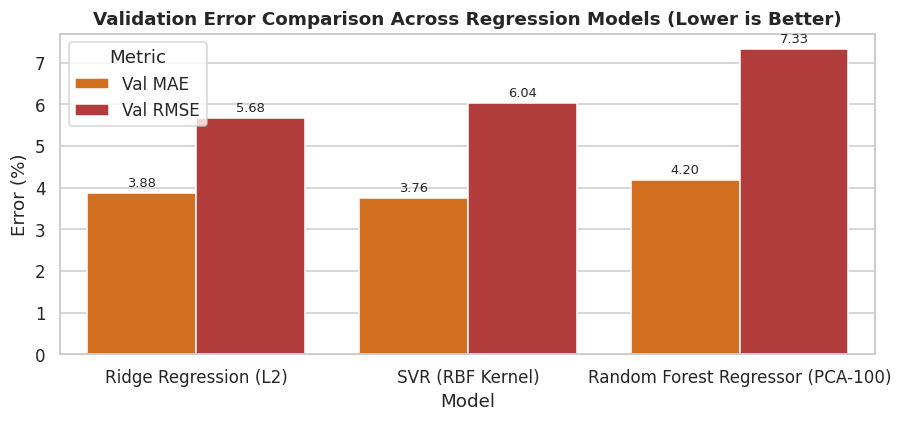


Test Regression (Ridge Regression (L2)) -> MAE: 4.388% | RMSE: 6.836% | R2: 0.6094


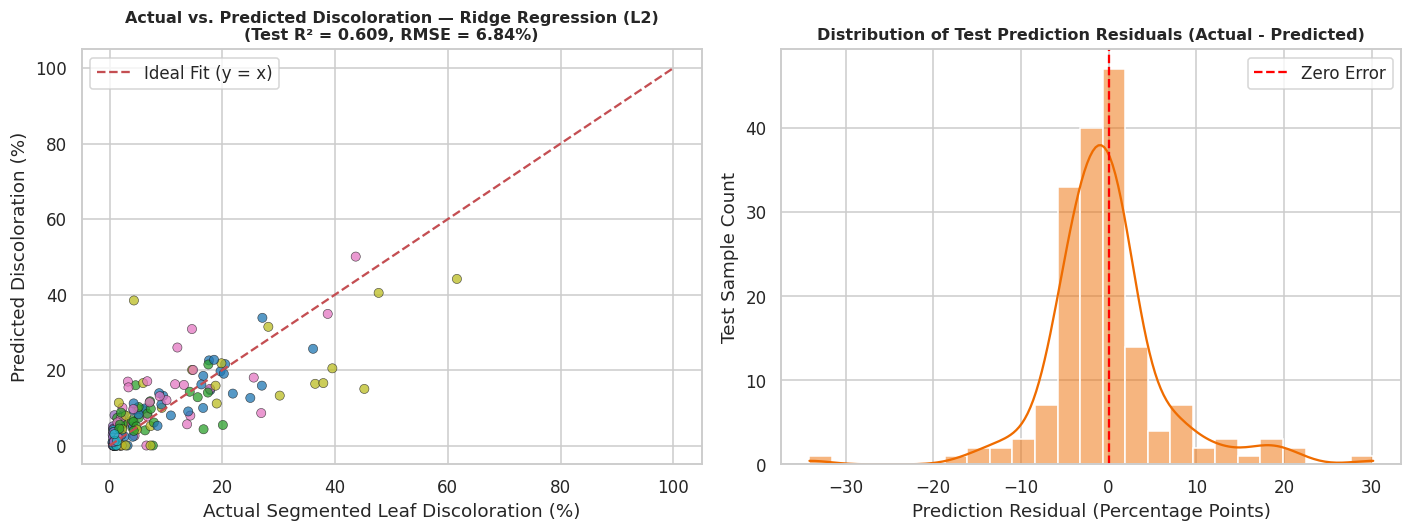

In [8]:
# Cell 8: Machine Learning Regression Pipeline & Diagnostic Plots
regressors = {
    "Ridge Regression (L2)": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=100.0, random_state=SEED)),
    ]),
    "SVR (RBF Kernel)": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", SVR(kernel="rbf", C=15.0, epsilon=1.0)),
    ]),
    "Random Forest Regressor (PCA-100)": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=pca_dim, random_state=SEED)),
        ("reg", RandomForestRegressor(n_estimators=250, random_state=SEED, n_jobs=-1)),
    ]),
}

reg_val_results = []
fitted_regressors = {}

for name, pipe in regressors.items():
    pipe.fit(X_train, y_reg_train)
    val_pred = np.clip(pipe.predict(X_val), 0.0, 100.0)
    mae = mean_absolute_error(y_reg_val, val_pred)
    rmse = float(np.sqrt(mean_squared_error(y_reg_val, val_pred)))
    r2 = r2_score(y_reg_val, val_pred)
    fitted_regressors[name] = pipe
    reg_val_results.append({"Model": name, "Val MAE": round(mae, 3), "Val RMSE": round(rmse, 3), "Val R2": round(r2, 4)})

reg_results_df = pd.DataFrame(reg_val_results).sort_values("Val RMSE", ascending=True)
display(reg_results_df)

# --- Visualization 9: Grouped Bar Chart Comparing Regression Error (MAE vs RMSE) ---
melted_reg = reg_results_df.melt(id_vars="Model", value_vars=["Val MAE", "Val RMSE"], var_name="Metric", value_name="Error (%)")
plt.figure(figsize=(8.5, 4))
ax = sns.barplot(data=melted_reg, x="Model", y="Error (%)", hue="Metric", palette=["#ef6c00", "#c62828"])
plt.title("Validation Error Comparison Across Regression Models (Lower is Better)", fontsize=12, fontweight="bold")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8.5)
plt.tight_layout()
plt.show()

# --- Evaluate Best Regressor on Untouched Test Set ---
best_reg_name = reg_results_df.iloc[0]["Model"]
best_reg_model = fitted_regressors[best_reg_name]
y_reg_test_pred = np.clip(best_reg_model.predict(X_test), 0.0, 100.0)

test_mae = mean_absolute_error(y_reg_test, y_reg_test_pred)
test_rmse = float(np.sqrt(mean_squared_error(y_reg_test, y_reg_test_pred)))
test_r2 = r2_score(y_reg_test, y_reg_test_pred)
print(f"\nTest Regression ({best_reg_name}) -> MAE: {test_mae:.3f}% | RMSE: {test_rmse:.3f}% | R2: {test_r2:.4f}")

# --- Visualization 10 & 11: Actual vs. Predicted Scatter & Residual Diagnostics ---
residuals = y_reg_test - y_reg_test_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

scatter = axes[0].scatter(
    y_reg_test,
    y_reg_test_pred,
    c=y_cls_test,
    cmap="tab10",
    alpha=0.75,
    edgecolors="k",
    linewidth=0.4,
)
axes[0].plot([0, 100], [0, 100], "r--", linewidth=1.5, label="Ideal Fit (y = x)")
axes[0].set_title(f"Actual vs. Predicted Discoloration — {best_reg_name}\n(Test R² = {test_r2:.3f}, RMSE = {test_rmse:.2f}%)", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Actual Segmented Leaf Discoloration (%)")
axes[0].set_ylabel("Predicted Discoloration (%)")
axes[0].legend()

sns.histplot(residuals, kde=True, bins=25, color="#ef6c00", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error")
axes[1].set_title("Distribution of Test Prediction Residuals (Actual - Predicted)", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("Prediction Residual (Percentage Points)")
axes[1].set_ylabel("Test Sample Count")
axes[1].legend()

plt.tight_layout()
plt.show()

Total test classification errors: 13 / 173


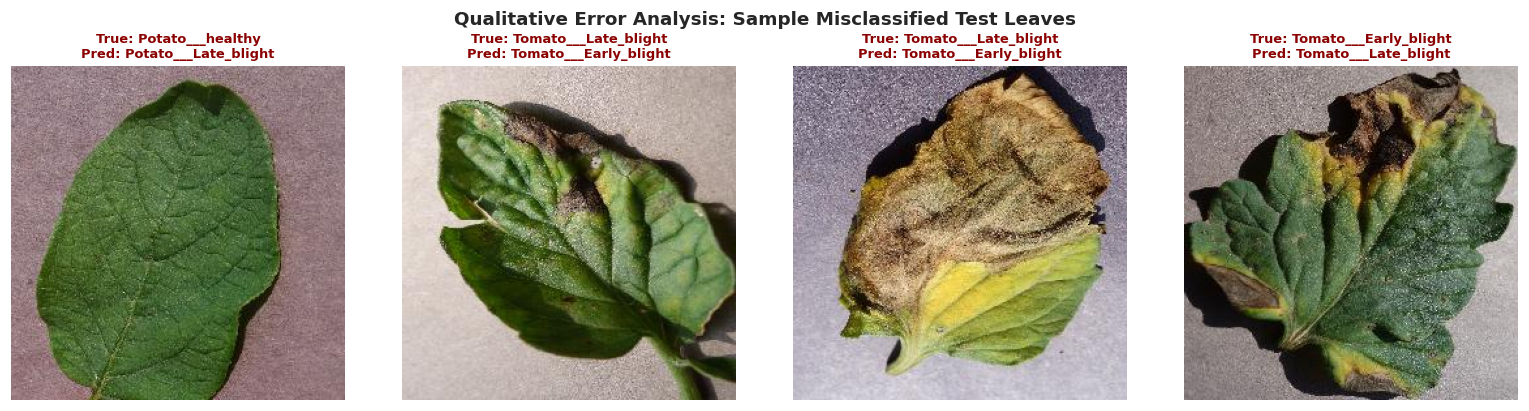

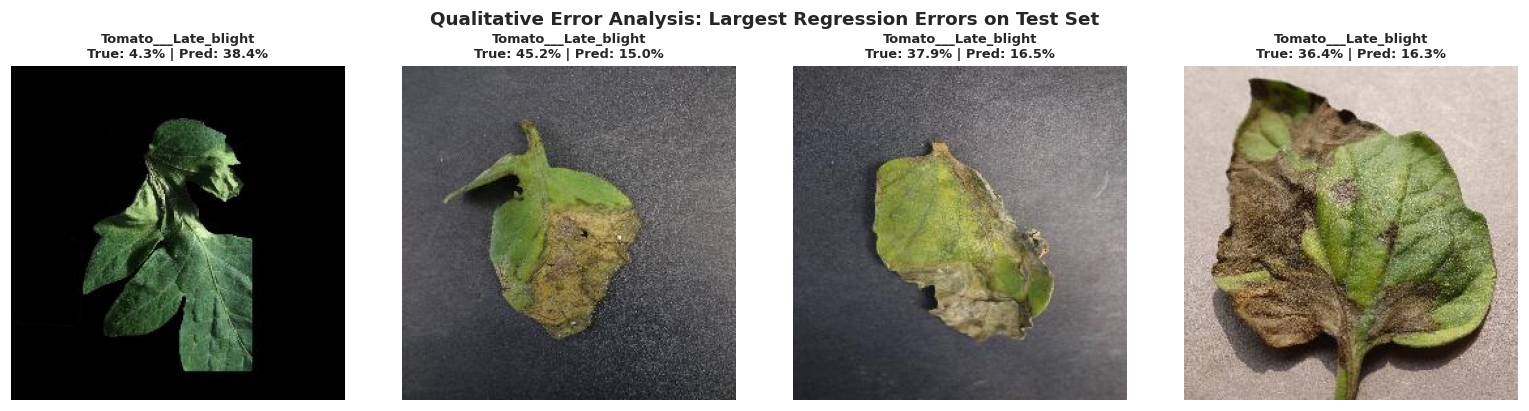

Saved trained models to: /content/agrigenius_ml_artifacts
Pipeline execution complete successfully!


In [9]:
# Cell 9: Qualitative Visual Error Inspection & Artifact Export
# --- Visualization 12: Misclassified Test Images Gallery ---
mis_idx = np.where(y_cls_test_pred != y_cls_test)[0]
print(f"Total test classification errors: {len(mis_idx)} / {len(y_cls_test)}")

if len(mis_idx) > 0:
    sample_mis = mis_idx[:4]
    fig, axes = plt.subplots(1, len(sample_mis), figsize=(3.6 * len(sample_mis), 3.8))
    if len(sample_mis) == 1:
        axes = [axes]
    for ax, idx in zip(axes, sample_mis):
        img = Image.open(test_df.loc[idx, "color_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"True: {class_names[y_cls_test[idx]]}\nPred: {class_names[y_cls_test_pred[idx]]}",
            fontsize=8.5,
            color="darkred",
            fontweight="bold",
        )
        ax.axis("off")
    plt.suptitle("Qualitative Error Analysis: Sample Misclassified Test Leaves", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

# --- Visualization 13: Worst Regression Errors Gallery ---
abs_err = np.abs(y_reg_test - y_reg_test_pred)
worst_reg_idx = np.argsort(abs_err)[::-1][:4]
fig, axes = plt.subplots(1, len(worst_reg_idx), figsize=(3.6 * len(worst_reg_idx), 3.8))
for ax, idx in zip(axes, worst_reg_idx):
    img = Image.open(test_df.loc[idx, "color_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f"{test_df.loc[idx, 'class_name']}\nTrue: {y_reg_test[idx]:.1f}% | Pred: {y_reg_test_pred[idx]:.1f}%",
        fontsize=8.5,
        fontweight="bold",
    )
    ax.axis("off")
plt.suptitle("Qualitative Error Analysis: Largest Regression Errors on Test Set", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# --- Save Models & Label Encoder ---
joblib.dump(best_cls_model, ARTIFACT_DIR / "best_classifier.joblib")
joblib.dump(best_reg_model, ARTIFACT_DIR / "best_regressor.joblib")
joblib.dump(le, ARTIFACT_DIR / "label_encoder.joblib")

print("Saved trained models to:", ARTIFACT_DIR.resolve())
print("Pipeline execution complete successfully!")